<a href="https://colab.research.google.com/github/AntonyRMV26/GRUPO-1---Ingenier-a-del-Conocimiento/blob/main/Actividad1_ML_OnlineShoppers.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

<div align="center">

# 🛒 Predicción de la Intención de Compra de Clientes en una Tienda en Línea

### UNIVERSIDAD NACIONAL DEL CENTRO DEL PERÚ
**Facultad de Ingeniería de Sistemas**

**Evaluación Parcial — Actividad 1: Pipeline de Machine Learning Clásico sobre Dataset Real**

</div>

---

# SECCIÓN A — Presentación

## 1. Datos generales

| | |
|---|---|
| **Curso** | Ingeniería del Conocimiento (ISO56B) |
| **Semestre** | V |
| **Fecha** | 23/10/2026 |
| **Docente** | Msc. Jaime Antonio Huaytalla Pariona |

## 2. Integrantes del grupo

| N.° | Apellidos y nombres | Código |
|:---:|---|---|
| 1 | Bendezu Arana, Joss Erick | *2024200180K* |
| 2 | Briceño Carrión, Polmar Yacid | *2024200182M* |
| 3 | Morales Huaman, Jhordan Aldair | *2024200194L* |
| 4 | Morales Valverde, Antony Rodrigo | *(completar)* |

## 3. Dataset elegido

- **Nombre:** Online Shoppers Purchasing Intention Dataset
- **Fuente (URL):** https://archive.ics.uci.edu/dataset/468/online+shoppers+purchasing+intention+dataset
- **Repositorio:** UCI Machine Learning Repository
- **Tipo de datos:** tabular, con 12 330 sesiones de navegación de una tienda en línea, 17 atributos (10 numéricos y 7 categóricos) y la variable objetivo `Revenue` (si la sesión terminó en compra o no).

### Justificación de la elección

Cuando revisamos los repositorios recomendados buscábamos un dataset que se sintiera cercano a algo que de verdad pasa hoy: el comercio electrónico. Este nos llamó la atención porque cada fila es una visita real a una tienda en línea y lo que se quiere saber es si esa visita termina en compra o no, algo que a cualquier negocio digital le interesa. Además cumple con lo que pide la consigna: es tabular, tiene bastante más de 500 registros, más de 5 variables, dos clases y son datos reales. También nos gustó porque mezcla variables numéricas con categóricas y tiene un **desbalance fuerte** (la gran mayoría de las sesiones no compra), lo que nos obliga a pensar bien qué métricas usar y no quedarnos solo con el accuracy. Por último, es un dataset que no habíamos trabajado en clase ni en los laboratorios.

## 4. Descripción del problema

El problema que planteamos es de **clasificación binaria**: a partir de cómo navega un usuario en la tienda (cuántas páginas visita, cuánto tiempo pasa en ellas, tasas de rebote y de salida, el valor de las páginas, el mes, el tipo de visitante, etc.) queremos predecir si la sesión termina en una compra (`Revenue = 1`) o no (`Revenue = 0`). Como solo una pequeña parte de las visitas compra, el modelo no puede limitarse a decir "no compra" siempre; tiene que detectar bien a la clase minoritaria. Para resolverlo armamos un pipeline completo: análisis exploratorio, preprocesamiento, cuatro modelos (Random Forest, XGBoost, Regresión Logística y SVM), comparación, optimización de hiperparámetros y serialización del modelo final.

---
# SECCIÓN B — Carga y Análisis Exploratorio de Datos (EDA)

## 0. Configuración inicial
Importamos las librerías y fijamos una **semilla** (`random_state = 42`) para que todo el notebook sea reproducible.

In [ ]:
# ------------------------------------------------------------
# Importación de librerías y configuración global
# ------------------------------------------------------------
import io, sys, time, zipfile, warnings, subprocess, urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib

from sklearn.base import clone
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV, cross_validate, cross_val_score
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from xgboost import XGBClassifier
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, roc_auc_score, roc_curve,
                             average_precision_score, precision_recall_curve)
from IPython.display import display, Markdown

warnings.filterwarnings("ignore")
SEED = 42
np.random.seed(SEED)

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams.update({"figure.dpi": 110, "axes.titlesize": 12,
                     "axes.titleweight": "bold", "axes.labelsize": 10})
pd.set_option("display.max_columns", 30)
print("Librerías cargadas correctamente.")

Librerías cargadas correctamente.


## 1. Carga del dataset
Cargamos el dataset directamente desde la URL pública de UCI (archivo `.zip` oficial). Por si la descarga fallara, el código tiene dos alternativas: el paquete `ucimlrepo` y la subida manual del archivo `online_shoppers_intention.csv`.

In [ ]:
# ------------------------------------------------------------
# Carga del dataset desde UCI (con alternativas de respaldo)
# ------------------------------------------------------------
URL_ZIP = "https://archive.ics.uci.edu/static/public/468/online+shoppers+purchasing+intention+dataset.zip"

def cargar_dataset():
    # Opción 1: descarga directa del zip oficial de UCI
    try:
        req = urllib.request.Request(URL_ZIP, headers={"User-Agent": "Mozilla/5.0"})
        with urllib.request.urlopen(req, timeout=60) as r:
            data = r.read()
        with zipfile.ZipFile(io.BytesIO(data)) as z:
            nombre = [n for n in z.namelist() if n.lower().endswith(".csv")][0]
            return pd.read_csv(z.open(nombre)), "descarga directa del zip de UCI"
    except Exception as e:
        print("Opción 1 falló:", e)
    # Opción 2: paquete ucimlrepo
    try:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", "ucimlrepo"])
        from ucimlrepo import fetch_ucirepo
        ds = fetch_ucirepo(id=468)
        return pd.concat([ds.data.features, ds.data.targets], axis=1), "paquete ucimlrepo"
    except Exception as e:
        print("Opción 2 falló:", e)
    # Opción 3: subir el CSV manualmente
    from google.colab import files
    print("Sube el archivo online_shoppers_intention.csv")
    subido = files.upload()
    return pd.read_csv(list(subido.keys())[0]), "archivo subido manualmente"

df, origen = cargar_dataset()

# Estandarizamos los tipos booleanos a enteros (0/1)
df["Revenue"] = df["Revenue"].astype(int)
df["Weekend"] = df["Weekend"].astype(int)
print(f"Dataset cargado vía: {origen}")

Dataset cargado vía: descarga directa del zip de UCI


## 2. Primeras filas, shape, tipos de datos y valores nulos

In [ ]:
# ------------------------------------------------------------
# Vista general del dataset
# ------------------------------------------------------------
print("Shape (filas, columnas):", df.shape)
display(df.head())

info_cols = pd.DataFrame({
    "Tipo de dato": df.dtypes.astype(str),
    "Valores nulos": df.isnull().sum(),
    "% nulos": (100 * df.isnull().mean()).round(2),
    "Valores únicos": df.nunique(),
})
display(info_cols)

n_nulos = int(df.isnull().sum().sum())
n_dup = int(df.duplicated().sum())
print(f"\nTotal de valores nulos: {n_nulos}")
print(f"Filas duplicadas      : {n_dup} ({100 * n_dup / len(df):.2f} %)")

Shape (filas, columnas): (12330, 18)


,Administrative,Administrative_Duration,Informational,Informational_Duration,ProductRelated,ProductRelated_Duration,BounceRates,ExitRates,PageValues,SpecialDay,Month,OperatingSystems,Browser,Region,TrafficType,VisitorType,Weekend,Revenue
0,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,1,1,1,1,Returning_Visitor,0,0
1,0,0.0,0,0.0,2,64.000000,0.00,0.10,0.0,0.0,Feb,2,2,1,2,Returning_Visitor,0,0
2,0,0.0,0,0.0,1,0.000000,0.20,0.20,0.0,0.0,Feb,4,1,9,3,Returning_Visitor,0,0
3,0,0.0,0,0.0,2,2.666667,0.05,0.14,0.0,0.0,Feb,3,2,2,4,Returning_Visitor,0,0
4,0,0.0,0,0.0,10,627.500000,0.02,0.05,0.0,0.0,Feb,3,3,1,4,Returning_Visitor,1,0


,Tipo de dato,Valores nulos,% nulos,Valores únicos
Administrative,int64,0,0.0,27
Administrative_Duration,float64,0,0.0,3335
Informational,int64,0,0.0,17
Informational_Duration,float64,0,0.0,1258
ProductRelated,int64,0,0.0,311
ProductRelated_Duration,float64,0,0.0,9551
BounceRates,float64,0,0.0,1872
ExitRates,float64,0,0.0,4777
PageValues,float64,0,0.0,2704
SpecialDay,float64,0,0.0,6



Total de valores nulos: 0
Filas duplicadas      : 125 (1.01 %)


## 3. Distribución de la variable objetivo (`Revenue`)
Graficamos el **conteo y el porcentaje** de sesiones que terminan en compra (`1`) y que no (`0`).

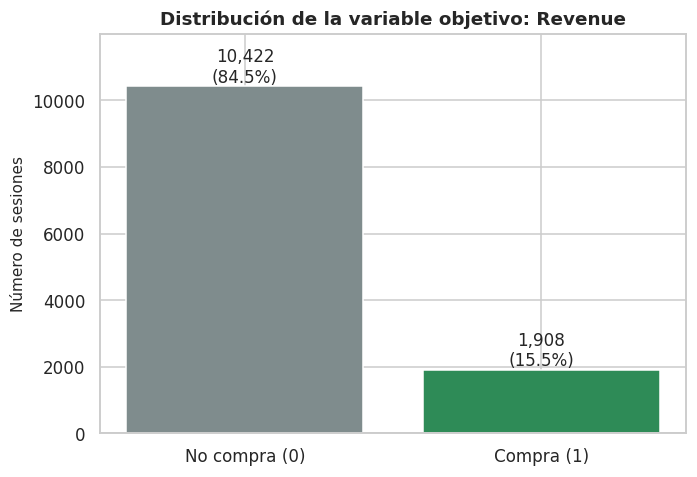

Relación entre clases: 5.5 sesiones sin compra por cada sesión con compra.


In [ ]:
# ------------------------------------------------------------
# Distribución de la variable objetivo con conteo y porcentaje
# ------------------------------------------------------------
conteo = df["Revenue"].value_counts().sort_index()
pct = 100 * conteo / conteo.sum()
etiquetas = ["No compra (0)", "Compra (1)"]

fig, ax = plt.subplots(figsize=(6.5, 4.5))
barras = ax.bar(etiquetas, conteo.values, color=["#7f8c8d", "#2e8b57"])
for b, c, p in zip(barras, conteo.values, pct.values):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 120, f"{c:,}\n({p:.1f}%)",
            ha="center", fontsize=11)
ax.set_ylim(0, conteo.max() * 1.15)
ax.set_title("Distribución de la variable objetivo: Revenue")
ax.set_ylabel("Número de sesiones")
plt.tight_layout(); plt.show()

ratio = conteo[0] / conteo[1]
print(f"Relación entre clases: {ratio:.1f} sesiones sin compra por cada sesión con compra.")

## 4. Estadísticas descriptivas de las variables numéricas

In [ ]:
# ------------------------------------------------------------
# Listas de columnas por tipo (se reutilizan en todo el notebook)
# ------------------------------------------------------------
num_cols = ["Administrative", "Administrative_Duration", "Informational", "Informational_Duration",
            "ProductRelated", "ProductRelated_Duration", "BounceRates", "ExitRates",
            "PageValues", "SpecialDay"]
cat_cols = ["Month", "OperatingSystems", "Browser", "Region", "TrafficType", "VisitorType"]
bin_cols = ["Weekend"]

desc = df[num_cols].describe().T
desc["asimetría"] = df[num_cols].skew()
display(desc.round(3))

,count,mean,std,min,25%,50%,75%,max,asimetría
Administrative,12330.0,2.315,3.322,0.0,0.000,1.000,4.000,27.000,1.960
Administrative_Duration,12330.0,80.819,176.779,0.0,0.000,7.500,93.256,3398.750,5.616
Informational,12330.0,0.504,1.270,0.0,0.000,0.000,0.000,24.000,4.036
Informational_Duration,12330.0,34.472,140.749,0.0,0.000,0.000,0.000,2549.375,7.579
ProductRelated,12330.0,31.731,44.476,0.0,7.000,18.000,38.000,705.000,4.342
ProductRelated_Duration,12330.0,1194.746,1913.669,0.0,184.138,598.937,1464.157,63973.522,7.263
BounceRates,12330.0,0.022,0.048,0.0,0.000,0.003,0.017,0.200,2.948
ExitRates,12330.0,0.043,0.049,0.0,0.014,0.025,0.050,0.200,2.149
PageValues,12330.0,5.889,18.568,0.0,0.000,0.000,0.000,361.764,6.383
SpecialDay,12330.0,0.061,0.199,0.0,0.000,0.000,0.000,1.000,3.303


## 5. Visualizaciones adicionales
Hicimos **6 visualizaciones** (la rúbrica pide al menos 2) para entender las variables, sus outliers y su relación con la compra.

### 5.1 Histogramas de las variables numéricas más relevantes

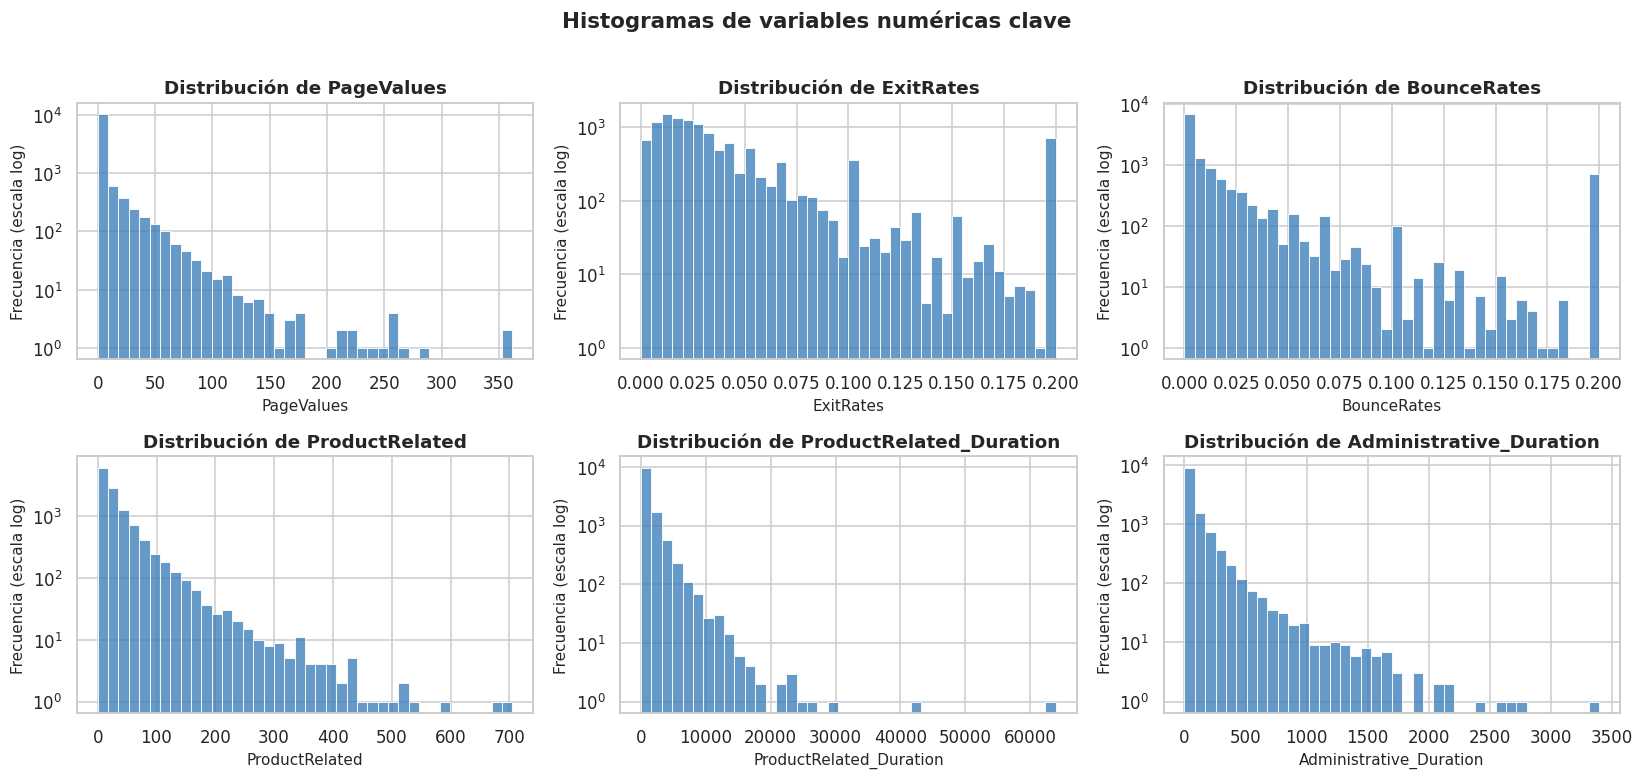

In [ ]:
# ------------------------------------------------------------
# Visualización 1: histogramas (eje Y logarítmico por la fuerte asimetría)
# ------------------------------------------------------------
vars_hist = ["PageValues", "ExitRates", "BounceRates", "ProductRelated",
             "ProductRelated_Duration", "Administrative_Duration"]
fig, axes = plt.subplots(2, 3, figsize=(15, 7))
for ax, v in zip(axes.ravel(), vars_hist):
    sns.histplot(df[v], bins=40, ax=ax, color="#337ab7")
    ax.set_yscale("log")
    ax.set_title(f"Distribución de {v}")
    ax.set_ylabel("Frecuencia (escala log)")
plt.suptitle("Histogramas de variables numéricas clave", fontsize=14, fontweight="bold", y=1.01)
plt.tight_layout(); plt.show()

### 5.2 Boxplots según la clase (detección de outliers y poder discriminante)

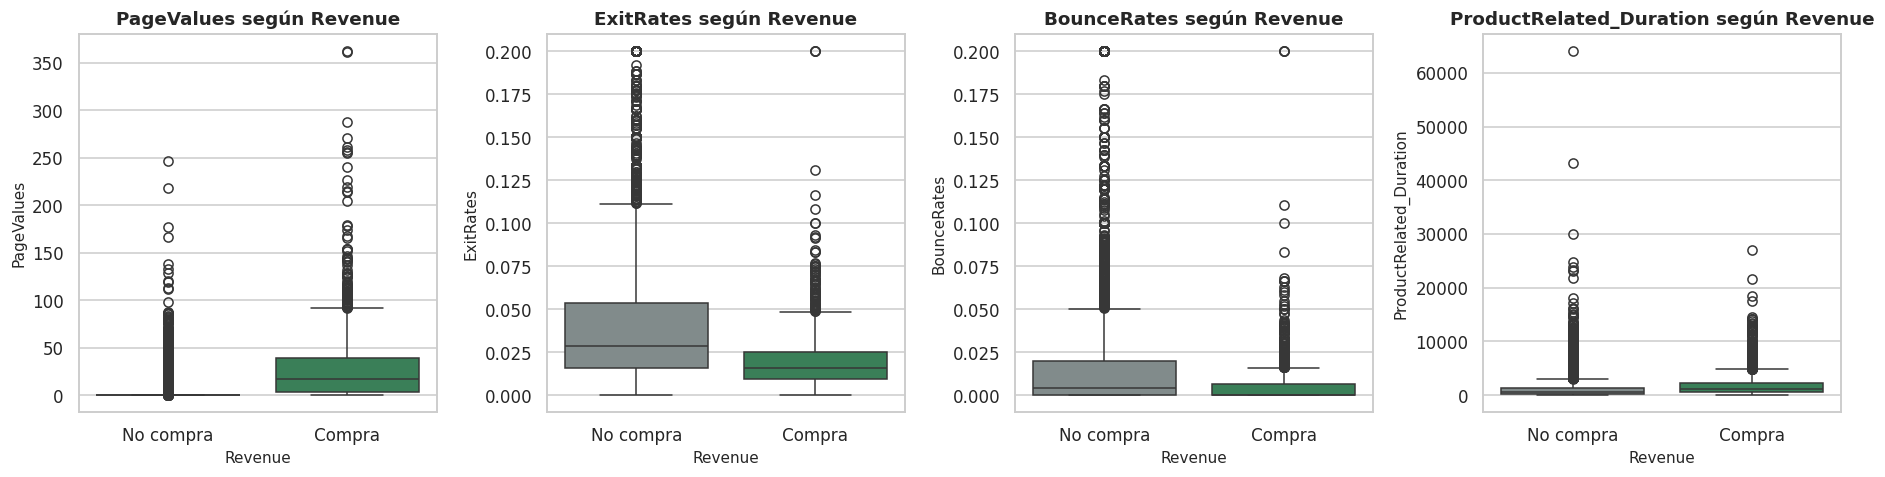

In [ ]:
# ------------------------------------------------------------
# Visualización 2: boxplots por clase de Revenue
# ------------------------------------------------------------
vars_box = ["PageValues", "ExitRates", "BounceRates", "ProductRelated_Duration"]
fig, axes = plt.subplots(1, 4, figsize=(17, 4.5))
for ax, v in zip(axes, vars_box):
    sns.boxplot(data=df, x="Revenue", y=v, ax=ax, palette=["#7f8c8d", "#2e8b57"])
    ax.set_xticklabels(["No compra", "Compra"])
    ax.set_title(f"{v} según Revenue")
plt.tight_layout(); plt.show()

### 5.3 Mapa de correlación

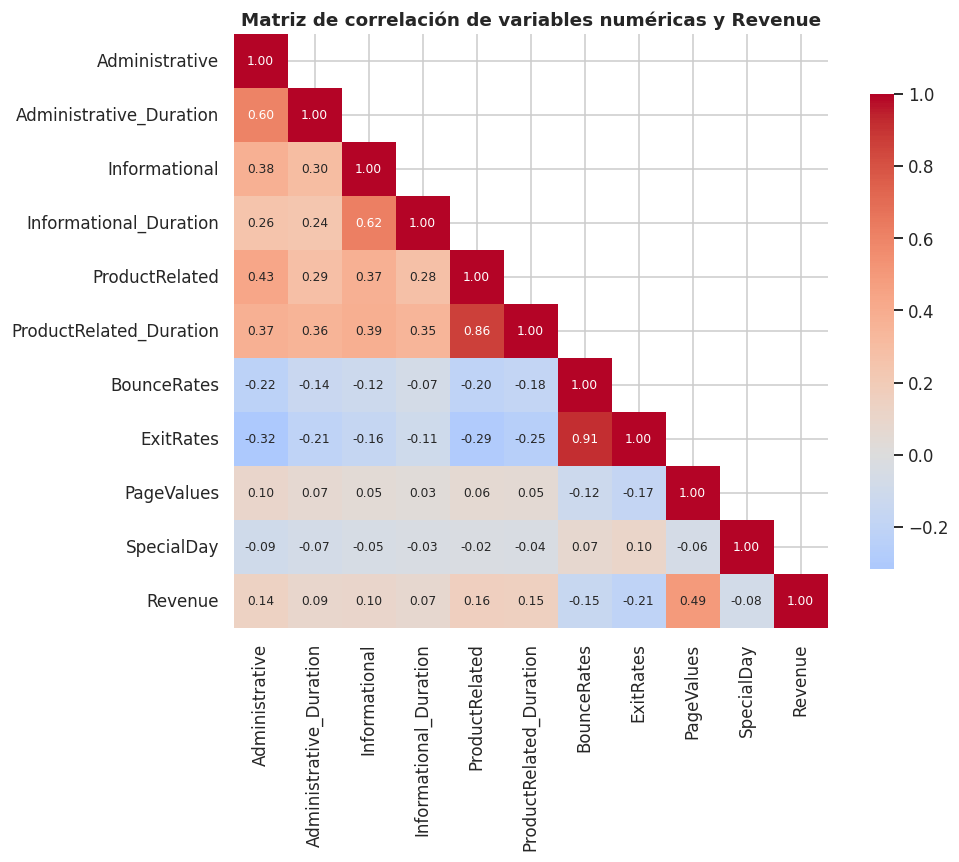

,Correlación con Revenue
PageValues,0.493
ProductRelated,0.159
ProductRelated_Duration,0.152
Administrative,0.139
Informational,0.095
Administrative_Duration,0.094
Informational_Duration,0.070
SpecialDay,-0.082
BounceRates,-0.151
ExitRates,-0.207


In [ ]:
# ------------------------------------------------------------
# Visualización 3: matriz de correlación (numéricas + objetivo)
# ------------------------------------------------------------
corr = df[num_cols + ["Revenue"]].corr()
plt.figure(figsize=(10, 8))
mask = np.triu(np.ones_like(corr, dtype=bool), k=1)
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="coolwarm", center=0,
            square=True, cbar_kws={"shrink": 0.8}, annot_kws={"size": 8})
plt.title("Matriz de correlación de variables numéricas y Revenue")
plt.tight_layout(); plt.show()

corr_rev = corr["Revenue"].drop("Revenue").sort_values(ascending=False)
display(corr_rev.rename("Correlación con Revenue").to_frame().round(3))

### 5.4 Tasa de compra por mes

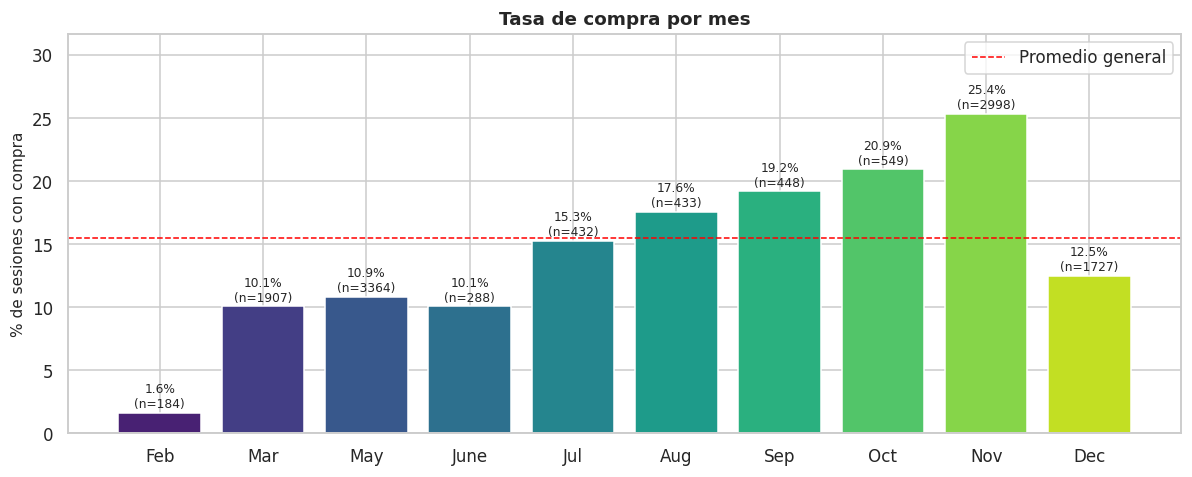

In [ ]:
# ------------------------------------------------------------
# Visualización 4: conversión (tasa de compra) por mes
# ------------------------------------------------------------
orden_meses = [m for m in ["Jan", "Feb", "Mar", "Apr", "May", "June", "Jul", "Aug", "Sep", "Oct", "Nov", "Dec"]
               if m in df["Month"].unique()]
tasa_mes = df.groupby("Month")["Revenue"].agg(["mean", "count"]).reindex(orden_meses)

fig, ax = plt.subplots(figsize=(11, 4.5))
barras = ax.bar(tasa_mes.index, 100 * tasa_mes["mean"], color=sns.color_palette("viridis", len(tasa_mes)))
for b, (m, fila) in zip(barras, tasa_mes.iterrows()):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.4,
            f"{100 * fila['mean']:.1f}%\n(n={int(fila['count'])})", ha="center", fontsize=8)
ax.axhline(100 * df["Revenue"].mean(), color="red", ls="--", lw=1, label="Promedio general")
ax.set_title("Tasa de compra por mes")
ax.set_ylabel("% de sesiones con compra"); ax.set_ylim(0, 100 * tasa_mes["mean"].max() * 1.25)
ax.legend(); plt.tight_layout(); plt.show()

### 5.5 Tasa de compra por tipo de visitante y por fin de semana

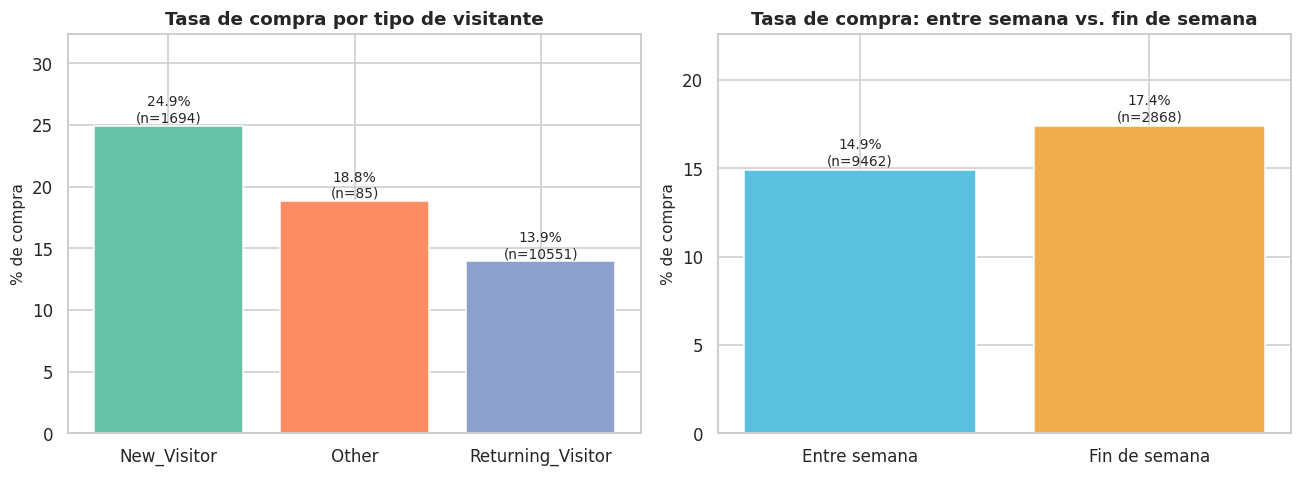

In [ ]:
# ------------------------------------------------------------
# Visualización 5: conversión por VisitorType y Weekend
# ------------------------------------------------------------
fig, ax = plt.subplots(1, 2, figsize=(12, 4.5))
tv = df.groupby("VisitorType")["Revenue"].agg(["mean", "count"])
b1 = ax[0].bar(tv.index, 100 * tv["mean"], color=sns.color_palette("Set2", len(tv)))
for b, (k, f) in zip(b1, tv.iterrows()):
    ax[0].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{100 * f['mean']:.1f}%\n(n={int(f['count'])})", ha="center", fontsize=9)
ax[0].set_title("Tasa de compra por tipo de visitante"); ax[0].set_ylabel("% de compra")
ax[0].set_ylim(0, 100 * tv["mean"].max() * 1.3)

tw = df.groupby("Weekend")["Revenue"].agg(["mean", "count"])
b2 = ax[1].bar(["Entre semana", "Fin de semana"], 100 * tw["mean"], color=["#5bc0de", "#f0ad4e"])
for b, (k, f) in zip(b2, tw.iterrows()):
    ax[1].text(b.get_x() + b.get_width() / 2, b.get_height() + 0.3, f"{100 * f['mean']:.1f}%\n(n={int(f['count'])})", ha="center", fontsize=9)
ax[1].set_title("Tasa de compra: entre semana vs. fin de semana"); ax[1].set_ylabel("% de compra")
ax[1].set_ylim(0, 100 * tw["mean"].max() * 1.3)
plt.tight_layout(); plt.show()

### 5.6 Pairplot de las variables más asociadas a la compra

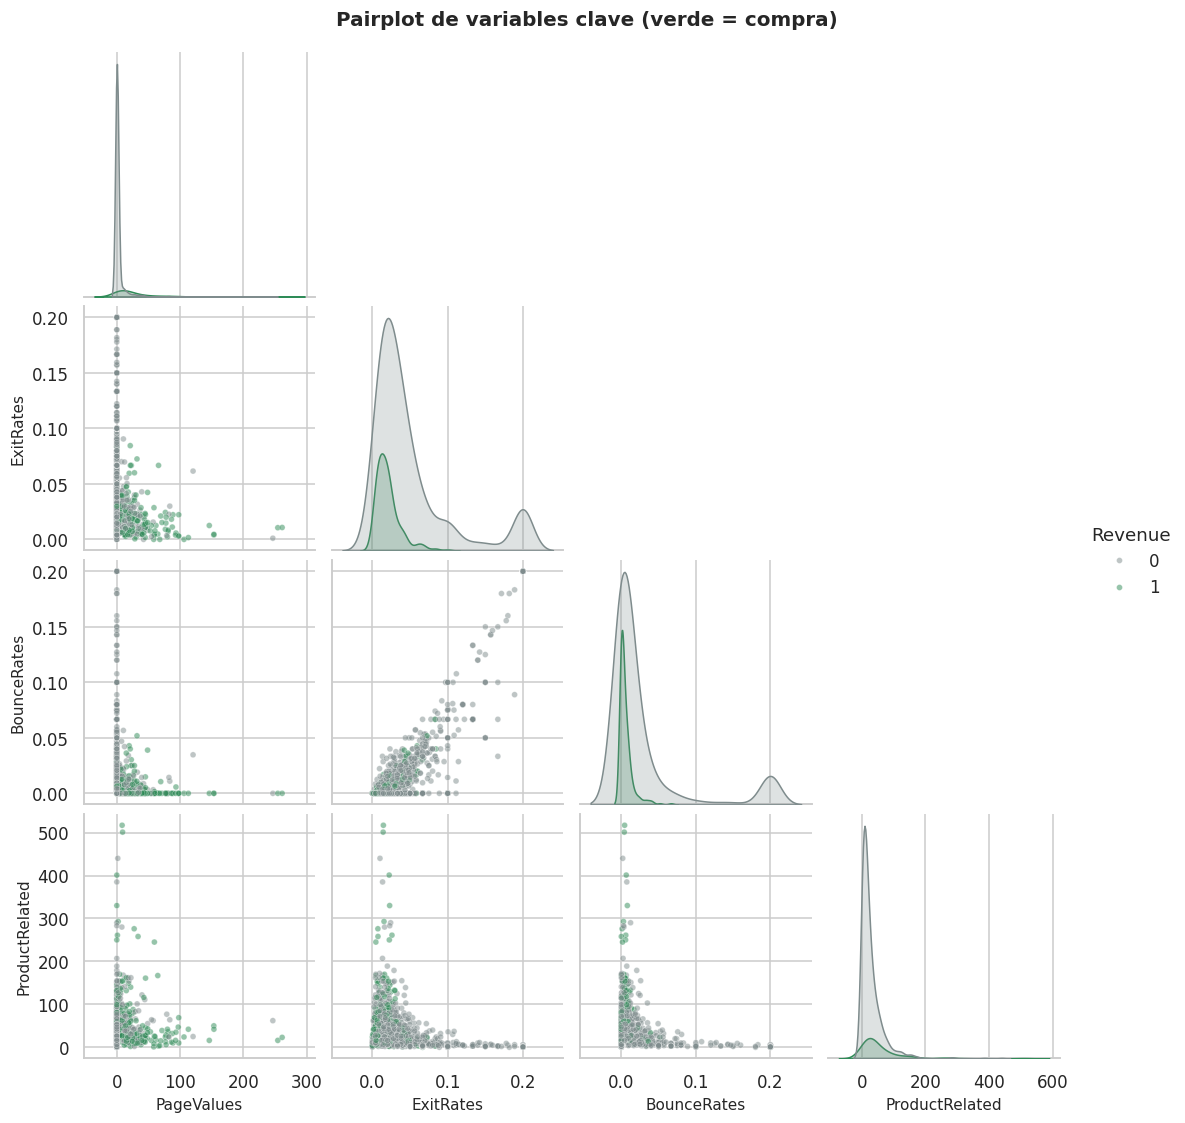

In [ ]:
# ------------------------------------------------------------
# Visualización 6: pairplot (muestra de 1 500 sesiones para que sea legible)
# ------------------------------------------------------------
muestra = df.sample(n=min(1500, len(df)), random_state=SEED)
g = sns.pairplot(muestra, vars=["PageValues", "ExitRates", "BounceRates", "ProductRelated"],
                 hue="Revenue", palette={0: "#7f8c8d", 1: "#2e8b57"}, plot_kws={"alpha": 0.5, "s": 15},
                 corner=True)
g.fig.suptitle("Pairplot de variables clave (verde = compra)", y=1.02, fontsize=13, fontweight="bold")
plt.show()

## 6. Conclusiones del EDA

**Hallazgos:** El dataset tiene 12,330 sesiones y 18 columnas; encontramos 0 valores nulos y 125 filas duplicadas. La variable objetivo está muy desbalanceada: solo el 15.5% de las sesiones termina en compra, es decir, 5.5 sesiones sin compra por cada una con compra, por lo que el accuracy por sí solo sería engañoso y vamos a priorizar F1 macro, AUC y el recall de la clase "compra". La variable más asociada a la compra es PageValues (correlación de 0.49 con Revenue), mientras que las tasas de rebote y de salida se relacionan de forma negativa con la compra y están fuertemente correlacionadas entre sí (r = 0.91), lo que sugiere redundancia. Las variables de duración y conteo de páginas son muy asimétricas (por ejemplo, ProductRelated_Duration tiene asimetría 7.3 y 7.8% de outliers según el IQR), así que conviene un modelo o un escalado que lo tolere. Por último, la conversión cambia con el calendario (Nov es el mes con mayor tasa y Feb el de menor entre los meses con al menos 100 sesiones) y con el tipo de visitante (New_Visitor es el que más compra).

**Decisiones de preprocesamiento:** (1) Eliminaremos las filas duplicadas antes del split para que no haya sesiones idénticas en train y test; (2) incluiremos un imputador como medida de seguridad ante nulos; (3) aplicaremos One-Hot a Month, VisitorType y a las columnas que son códigos (OperatingSystems, Browser, Region, TrafficType), y dejaremos Weekend como 0/1; (4) escalaremos las variables numéricas con StandardScaler, ajustado solo con train; (5) haremos un split 80/20 estratificado por Revenue y trataremos el desbalance con pesos de clase (sin SMOTE).

---
# SECCIÓN C — Preprocesamiento

## 1. Tratamiento de valores nulos y duplicados
**Estrategia y justificación:**
- **Nulos:** si el dataset trae valores nulos usaremos **imputación** (mediana en numéricas y moda en categóricas) en lugar de eliminar filas, porque eliminar sesiones reduciría aún más a la clase minoritaria. La imputación va **dentro del pipeline**, ajustada solo con datos de train, para evitar fuga de información. En la versión de UCI que cargamos el conteo de nulos fue el que vimos en la Sección B.
- **Duplicados:** los **eliminamos antes del split**. Si una sesión idéntica quedara una vez en train y otra en test, el modelo "vería" parte del test durante el entrenamiento y las métricas saldrían infladas.

In [ ]:
# ------------------------------------------------------------
# C.1: eliminación de duplicados y verificación de nulos
# ------------------------------------------------------------
n_antes = len(df)
df_clean = df.drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {n_antes:,} | después de eliminar duplicados: {len(df_clean):,} (se eliminaron {n_antes - len(df_clean)})")
print(f"Nulos restantes: {int(df_clean.isnull().sum().sum())}")
print(f"% de compra después de limpiar: {100 * df_clean['Revenue'].mean():.2f}% (antes: {100 * df['Revenue'].mean():.2f}%)")

X = df_clean.drop(columns="Revenue")
y = df_clean["Revenue"]

Filas antes: 12,330 | después de eliminar duplicados: 12,205 (se eliminaron 125)
Nulos restantes: 0
% de compra después de limpiar: 15.63% (antes: 15.47%)


## 2. Codificación de variables categóricas
- **`Month` y `VisitorType`** son texto → `OneHotEncoder`.
- **`OperatingSystems`, `Browser`, `Region`, `TrafficType`** vienen como números, pero son **códigos de categoría**, no cantidades (el sistema operativo "3" no es "mayor" que el "2"). Si los dejáramos numéricos, la regresión logística y la SVM interpretarían un orden que no existe. Por eso también van a `OneHotEncoder`.
- **`Weekend`** ya es binaria (0/1), se deja tal cual.
- Usamos `handle_unknown="ignore"` para que el modelo serializado no falle si en producción aparece una categoría nueva.

Elegimos **OneHotEncoder** y no LabelEncoder porque LabelEncoder impone un orden artificial entre categorías, algo problemático para modelos lineales y SVM.

## 3. Escalado de variables numéricas
Antes de elegir, miramos las escalas: las duraciones están en miles de segundos y las tasas de rebote/salida entre 0 y 1.

In [ ]:
# ------------------------------------------------------------
# C.3 (parte 1): diferencias de escala entre variables numéricas
# ------------------------------------------------------------
escalas = X[num_cols].agg(["min", "max", "mean", "std"]).T
display(escalas.round(3))

,min,max,mean,std
Administrative,0.0,27.000,2.339,3.330
Administrative_Duration,0.0,3398.750,81.646,177.492
Informational,0.0,24.000,0.509,1.276
Informational_Duration,0.0,2549.375,34.825,141.425
ProductRelated,0.0,705.000,32.046,44.594
ProductRelated_Duration,0.0,63973.522,1206.982,1919.601
BounceRates,0.0,0.200,0.020,0.045
ExitRates,0.0,0.200,0.041,0.046
PageValues,0.0,361.764,5.950,18.654
SpecialDay,0.0,1.000,0.062,0.200


**Elección: `StandardScaler`.** Regresión Logística y SVM (RBF) son sensibles a la escala: con las duraciones en miles, dominarían sobre las tasas entre 0 y 1. Preferimos StandardScaler sobre MinMaxScaler porque nuestras variables tienen **muchos outliers** (visto en el EDA): con MinMax, un solo valor extremo comprimiría casi todos los datos en un rango diminuto, mientras que StandardScaler los centra y los pone en una escala comparable sin depender del máximo. Los modelos de árboles (Random Forest, XGBoost) **no necesitan** escalado, pero lo aplicamos igual a los cuatro para que todos reciban exactamente la misma matriz de entrada y la comparación sea justa; en ellos no daña el resultado.

**Importante:** el escalador y el codificador se **ajustan solo con train** (`fit`) y luego se aplican a test (`transform`). Si los ajustáramos con todos los datos, la media y desviación del test se filtrarían al entrenamiento (*data leakage*). Por eso el orden práctico es: definir el preprocesador → hacer el split → ajustar con train.

In [ ]:
# ------------------------------------------------------------
# C.2 y C.3: preprocesador (imputación + escalado + one-hot)
# ------------------------------------------------------------
num_pipe = Pipeline([("imputer", SimpleImputer(strategy="median")),
                     ("scaler", StandardScaler())])
cat_pipe = Pipeline([("imputer", SimpleImputer(strategy="most_frequent")),
                     ("onehot", OneHotEncoder(handle_unknown="ignore", sparse_output=False))])

preprocessor = ColumnTransformer([
    ("num", num_pipe, num_cols),
    ("cat", cat_pipe, cat_cols),
    ("bin", "passthrough", bin_cols),
])
print(preprocessor)

ColumnTransformer(transformers=[('num',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='median')),
                                                 ('scaler', StandardScaler())]),
                                 ['Administrative', 'Administrative_Duration',
                                  'Informational', 'Informational_Duration',
                                  'ProductRelated', 'ProductRelated_Duration',
                                  'BounceRates', 'ExitRates', 'PageValues',
                                  'SpecialDay']),
                                ('cat',
                                 Pipeline(steps=[('imputer',
                                                  SimpleImputer(strategy='most_frequent')),
                                                 ('onehot',
                                                  OneHotEncoder(handle_unknown='ignore',
                              

## 4. Split train/test con estratificación
`test_size = 0.2`, `random_state = 42` y `stratify = y`, para que ambos conjuntos conserven la proporción de compras y no compras.

In [ ]:
# ------------------------------------------------------------
# C.4: split estratificado 80 / 20
# ------------------------------------------------------------
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, stratify=y, random_state=SEED
)

# Ajustamos el preprocesador SOLO con train y transformamos ambos
Xtr_p = preprocessor.fit_transform(X_train)
Xte_p = preprocessor.transform(X_test)
nombres_features = preprocessor.get_feature_names_out()

print(f"Train: {X_train.shape} -> {Xtr_p.shape} tras el preprocesamiento")
print(f"Test : {X_test.shape} -> {Xte_p.shape}")
print(f"Número de features finales: {len(nombres_features)}")

Train: (9764, 17) -> (9764, 73) tras el preprocesamiento
Test : (2441, 17) -> (2441, 73)
Número de features finales: 73


## 5. Verificación de la distribución de clases en train y test

,No compra (0),Compra (1),% Compra
Total,10297.0,1908.0,15.63
Train,8238.0,1526.0,15.63
Test,2059.0,382.0,15.65


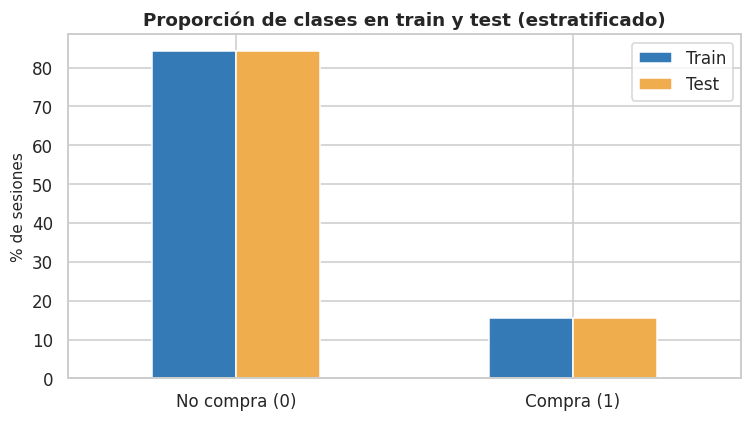

scale_pos_weight (XGBoost) = 8238/1526 = 5.40


In [ ]:
# ------------------------------------------------------------
# C.5: verificación de la estratificación
# ------------------------------------------------------------
def dist(y_):
    c = y_.value_counts().sort_index()
    return pd.Series({"No compra (0)": c[0], "Compra (1)": c[1],
                      "% Compra": round(100 * c[1] / c.sum(), 2)})

tabla_dist = pd.DataFrame({"Total": dist(y), "Train": dist(y_train), "Test": dist(y_test)}).T
display(tabla_dist)

fig, ax = plt.subplots(figsize=(7, 4))
prop = pd.DataFrame({"Train": y_train.value_counts(normalize=True).sort_index() * 100,
                     "Test": y_test.value_counts(normalize=True).sort_index() * 100})
prop.index = ["No compra (0)", "Compra (1)"]
prop.plot(kind="bar", ax=ax, rot=0, color=["#337ab7", "#f0ad4e"])
ax.set_title("Proporción de clases en train y test (estratificado)")
ax.set_ylabel("% de sesiones")
plt.tight_layout(); plt.show()

# Peso para XGBoost: negativos / positivos en train
neg, pos = int((y_train == 0).sum()), int((y_train == 1).sum())
scale_pos = neg / pos
print(f"scale_pos_weight (XGBoost) = {neg}/{pos} = {scale_pos:.2f}")

---
# SECCIÓN D — Modelado (4 modelos)

## 1. Modelos elegidos y justificación
El grupo investigó el dataset y llegó a estos cuatro candidatos. Cada uno aporta algo distinto:

| Modelo | Por qué encaja con este dataset | Cómo tratamos el desbalance |
|---|---|---|
| **Random Forest** | Maneja variables mixtas, relaciones no lineales y outliers (muy presentes en las duraciones). | `class_weight="balanced"` |
| **XGBoost** (Gradient Boosting) | Suele ser el mejor en datos tabulares y capta interacciones (p. ej. `PageValues` con tipo de visitante). | `scale_pos_weight` |
| **Regresión Logística** | Baseline **interpretable**: sus coeficientes explican qué factores empujan la compra. | `class_weight="balanced"` |
| **SVM (kernel RBF)** | Frontera de decisión no lineal flexible sobre datos escalados. | `class_weight="balanced"` |

Para **todos**: entrenamos con train, predecimos sobre test, mostramos el `classification_report` y una matriz de confusión con heatmap. La consigna lista RandomForest, SVM y GradientBoosting; XGBoost es una implementación optimizada de Gradient Boosting, y la Regresión Logística también está en la lista.

In [ ]:
# ------------------------------------------------------------
# D.1: definición de los 4 modelos
# ------------------------------------------------------------
modelos = {
    "Random Forest": RandomForestClassifier(
        n_estimators=300, class_weight="balanced", min_samples_leaf=2,
        n_jobs=-1, random_state=SEED),
    "XGBoost": XGBClassifier(
        n_estimators=300, learning_rate=0.05, max_depth=4, subsample=0.8,
        colsample_bytree=0.8, scale_pos_weight=scale_pos, eval_metric="logloss",
        tree_method="hist", n_jobs=-1, random_state=SEED),
    "Regresión Logística": LogisticRegression(
        max_iter=2000, class_weight="balanced", random_state=SEED),
    "SVM (RBF)": SVC(
        kernel="rbf", C=1.0, gamma="scale", class_weight="balanced", random_state=SEED),
}

resultados, scores_test, preds_test, entrenados = {}, {}, {}, {}

def puntuaciones(modelo, X_):
    # Probabilidad de la clase 1; la SVM usa decision_function (más rápido que probability=True)
    if hasattr(modelo, "predict_proba"):
        return modelo.predict_proba(X_)[:, 1]
    return modelo.decision_function(X_)

def plot_cm(y_true, y_pred, titulo):
    cm = confusion_matrix(y_true, y_pred)
    cm_n = cm / cm.sum(axis=1, keepdims=True)
    etq = ["No compra", "Compra"]
    fig, ax = plt.subplots(1, 2, figsize=(11, 4))
    sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=etq, yticklabels=etq, cbar=False, ax=ax[0], annot_kws={"size": 13})
    ax[0].set_title(f"{titulo} — conteos"); ax[0].set_xlabel("Predicho"); ax[0].set_ylabel("Real")
    sns.heatmap(cm_n, annot=True, fmt=".1%", cmap="Greens", xticklabels=etq, yticklabels=etq, cbar=False, ax=ax[1], annot_kws={"size": 13}, vmin=0, vmax=1)
    ax[1].set_title(f"{titulo} — % por fila"); ax[1].set_xlabel("Predicho"); ax[1].set_ylabel("Real")
    plt.tight_layout(); plt.show()

def entrenar_y_evaluar(nombre):
    modelo = modelos[nombre]
    t0 = time.time(); modelo.fit(Xtr_p, y_train); t_fit = time.time() - t0
    t0 = time.time(); y_pred = modelo.predict(Xte_p); t_pred = time.time() - t0
    s = puntuaciones(modelo, Xte_p)

    print(f"===== {nombre} =====")
    print(f"Tiempo de entrenamiento: {t_fit:.1f} s | Tiempo de predicción: {t_pred:.2f} s\n")
    print(classification_report(y_test, y_pred, target_names=["No compra", "Compra"], digits=4))
    plot_cm(y_test, y_pred, nombre)

    entrenados[nombre], preds_test[nombre], scores_test[nombre] = modelo, y_pred, s
    resultados[nombre] = {
        "Accuracy": accuracy_score(y_test, y_pred),
        "Precision (compra)": precision_score(y_test, y_pred),
        "Recall (compra)": recall_score(y_test, y_pred),
        "F1 (compra)": f1_score(y_test, y_pred),
        "F1 macro": f1_score(y_test, y_pred, average="macro"),
        "AUC": roc_auc_score(y_test, s),
        "AP (PR-AUC)": average_precision_score(y_test, s),
        "Tiempo entrenamiento (s)": t_fit,
    }

## 2–4. Entrenamiento, predicción, reporte y matriz de confusión por modelo

### 🌲 Modelo 1: Random Forest

===== Random Forest =====
Tiempo de entrenamiento: 5.0 s | Tiempo de predicción: 0.15 s

              precision    recall  f1-score   support

   No compra     0.9416    0.9398    0.9407      2059
      Compra     0.6788    0.6859    0.6823       382

    accuracy                         0.9000      2441
   macro avg     0.8102    0.8128    0.8115      2441
weighted avg     0.9005    0.9000    0.9003      2441



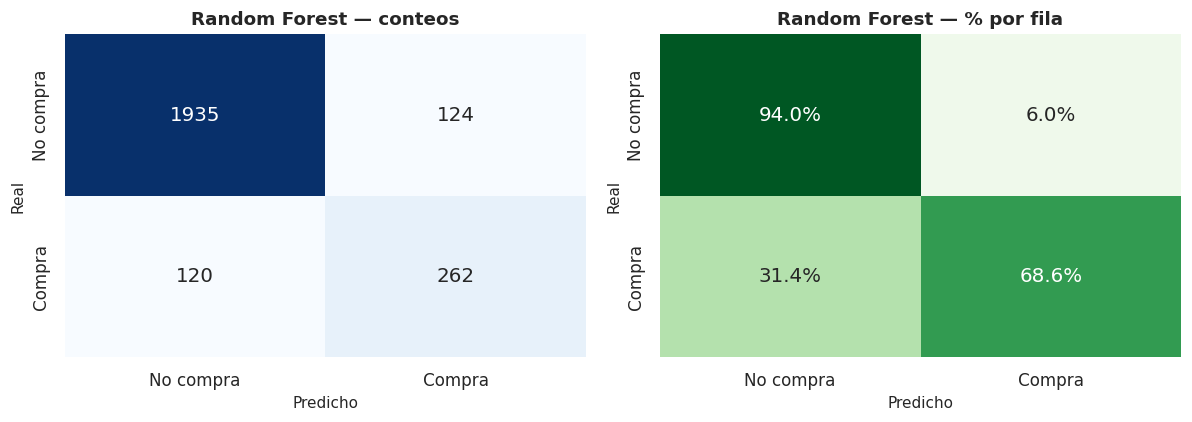

In [ ]:
entrenar_y_evaluar("Random Forest")

### 🚀 Modelo 2: XGBoost

In [ ]:
entrenar_y_evaluar("XGBoost")

### 📈 Modelo 3: Regresión Logística

===== Regresión Logística =====
Tiempo de entrenamiento: 0.7 s | Tiempo de predicción: 0.00 s

              precision    recall  f1-score   support

   No compra     0.9577    0.8572    0.9047      2059
      Compra     0.5084    0.7958    0.6204       382

    accuracy                         0.8476      2441
   macro avg     0.7330    0.8265    0.7625      2441
weighted avg     0.8874    0.8476    0.8602      2441



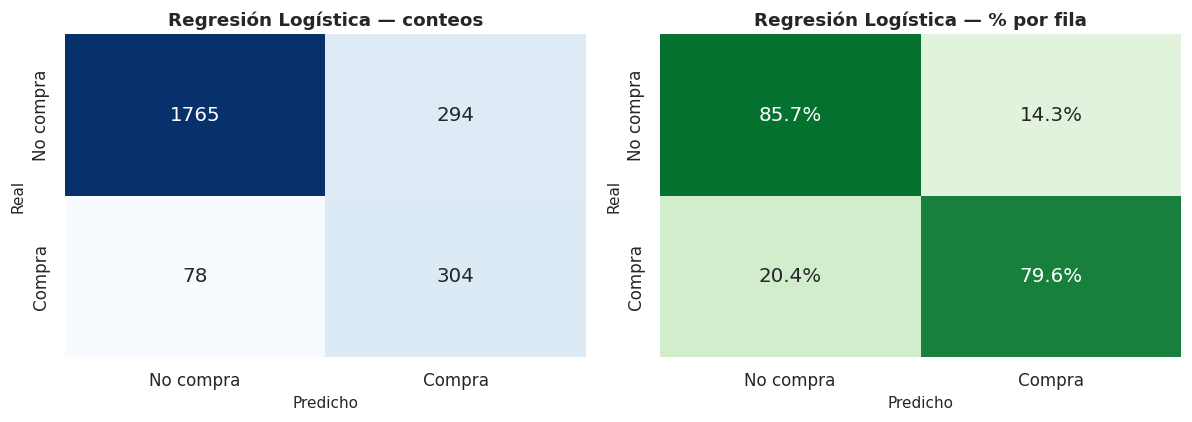

In [ ]:
entrenar_y_evaluar("Regresión Logística")

### 🎯 Modelo 4: SVM (kernel RBF)

===== SVM (RBF) =====
Tiempo de entrenamiento: 5.1 s | Tiempo de predicción: 1.18 s

              precision    recall  f1-score   support

   No compra     0.9537    0.8898    0.9206      2059
      Compra     0.5635    0.7670    0.6497       382

    accuracy                         0.8705      2441
   macro avg     0.7586    0.8284    0.7851      2441
weighted avg     0.8926    0.8705    0.8782      2441



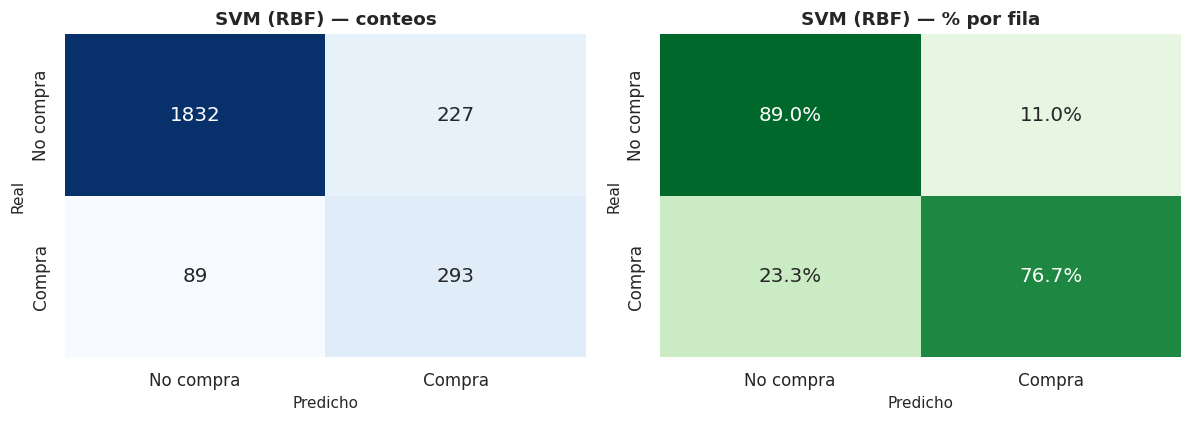

In [ ]:
entrenar_y_evaluar("SVM (RBF)")

## 5. Validación cruzada estratificada (5 folds) sobre train
Un solo split de test puede ser engañoso, sobre todo con una clase minoritaria. Por eso medimos también la **estabilidad** de cada modelo con validación cruzada estratificada de 5 folds sobre el conjunto de train. Usamos un `Pipeline` completo (preprocesamiento + modelo), de modo que en cada fold el escalado y el one-hot se ajustan solo con los datos de entrenamiento de ese fold. Esta tabla también será nuestro criterio para **elegir el mejor modelo** en la Sección F, ya que así no usamos el test para decidir.

In [ ]:
# ------------------------------------------------------------
# D.5: validación cruzada estratificada con Pipeline (sin fuga de datos)
# ------------------------------------------------------------
skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)
scoring_cv = {"f1_macro": "f1_macro", "roc_auc": "roc_auc", "recall": "recall", "accuracy": "accuracy"}

filas_cv = {}
for nombre, modelo in modelos.items():
    pipe = Pipeline([("prep", clone(preprocessor)), ("clf", clone(modelo))])
    cv = cross_validate(pipe, X_train, y_train, cv=skf, scoring=scoring_cv, n_jobs=-1)
    filas_cv[nombre] = {
        "CV F1 macro (media)": cv["test_f1_macro"].mean(), "CV F1 macro (std)": cv["test_f1_macro"].std(),
        "CV AUC (media)": cv["test_roc_auc"].mean(), "CV Recall compra (media)": cv["test_recall"].mean(),
        "CV Accuracy (media)": cv["test_accuracy"].mean(),
    }

tabla_cv = pd.DataFrame(filas_cv).T
display(tabla_cv.style.format("{:.4f}").highlight_max(color="#c8e6c9", axis=0))

## 6. Exploración de hiperparámetros
Antes de la optimización formal de la Sección F, hicimos una **exploración rápida** de un hiperparámetro clave por modelo (validación cruzada de 3 folds, métrica F1 macro) para entender su sensibilidad:

| Modelo | Hiperparámetro explorado |
|---|---|
| Random Forest | `max_depth` (profundidad de los árboles) |
| XGBoost | `max_depth` |
| Regresión Logística | `C` (inverso de la regularización) |
| SVM | `C` (penalización de errores) |

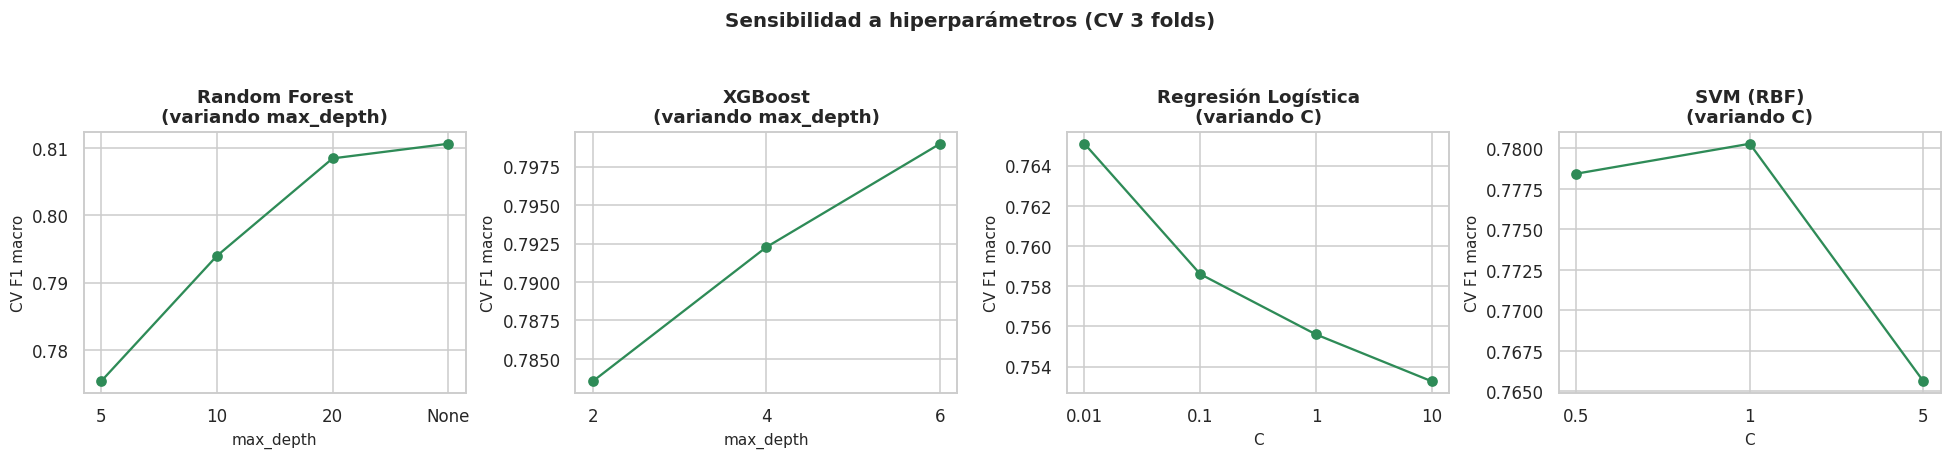

,Modelo,Hiperparámetro,Valor,CV F1 macro
0,Random Forest,max_depth,5,0.7753
1,Random Forest,max_depth,10,0.7940
2,Random Forest,max_depth,20,0.8085
3,Random Forest,max_depth,None,0.8107
4,XGBoost,max_depth,2,0.7835
5,XGBoost,max_depth,4,0.7923
6,XGBoost,max_depth,6,0.7990
7,Regresión Logística,C,0.01,0.7651
8,Regresión Logística,C,0.1,0.7586
9,Regresión Logística,C,1,0.7556


In [ ]:
# ------------------------------------------------------------
# D.6: exploración rápida de un hiperparámetro por modelo
# ------------------------------------------------------------
exploracion = {
    "Random Forest": ("max_depth", [5, 10, 20, None]),
    "XGBoost": ("max_depth", [2, 4, 6]),
    "Regresión Logística": ("C", [0.01, 0.1, 1, 10]),
    "SVM (RBF)": ("C", [0.5, 1, 5]),
}
skf3 = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)

fig, axes = plt.subplots(1, 4, figsize=(18, 4))
filas_exp = []
for ax, (nombre, (hp, valores)) in zip(axes, exploracion.items()):
    medias = []
    for v in valores:
        m = clone(modelos[nombre]).set_params(**{hp: v})
        pipe = Pipeline([("prep", clone(preprocessor)), ("clf", m)])
        sc = cross_val_score(pipe, X_train, y_train, cv=skf3, scoring="f1_macro", n_jobs=-1).mean()
        medias.append(sc); filas_exp.append({"Modelo": nombre, "Hiperparámetro": hp, "Valor": str(v), "CV F1 macro": sc})
    ax.plot([str(v) for v in valores], medias, "o-", color="#2e8b57")
    ax.set_title(f"{nombre}\n(variando {hp})"); ax.set_xlabel(hp); ax.set_ylabel("CV F1 macro")
plt.suptitle("Sensibilidad a hiperparámetros (CV 3 folds)", fontsize=13, fontweight="bold", y=1.04)
plt.tight_layout(); plt.show()
display(pd.DataFrame(filas_exp).round(4))

---
# SECCIÓN E — Evaluación Comparativa

## 1. Tabla resumen de métricas (sobre test)
Incluimos accuracy, **F1 macro**, **AUC** y, por el desbalance, precision/recall/F1 de la clase "compra" y el AP (área bajo la curva Precision-Recall), junto con los resultados de validación cruzada.

In [ ]:
# ------------------------------------------------------------
# E.1: tabla resumen de todos los modelos
# ------------------------------------------------------------
df_res = pd.DataFrame(resultados).T
df_res = df_res.join(tabla_cv[["CV F1 macro (media)", "CV F1 macro (std)", "CV AUC (media)"]])
df_res = df_res.sort_values("F1 macro", ascending=False)

fmt = {c: "{:.4f}" for c in df_res.columns}
fmt["Tiempo entrenamiento (s)"] = "{:.1f}"
cols_max = [c for c in df_res.columns if c not in ("Tiempo entrenamiento (s)", "CV F1 macro (std)")]
display(df_res.style.format(fmt).highlight_max(subset=cols_max, color="#c8e6c9")
        .highlight_min(subset=["Tiempo entrenamiento (s)"], color="#c8e6c9"))

## 2. Gráfico de barras comparando el rendimiento

In [ ]:
# ------------------------------------------------------------
# E.2: gráfico de barras agrupadas
# ------------------------------------------------------------
metricas_graf = ["Accuracy", "F1 macro", "AUC", "Recall (compra)"]
orden = df_res.index.tolist()
x = np.arange(len(orden)); w = 0.2
colores_m = ["#7f8c8d", "#2e8b57", "#337ab7", "#f0ad4e"]

fig, ax = plt.subplots(figsize=(12, 5.5))
for i, (m, c) in enumerate(zip(metricas_graf, colores_m)):
    barras = ax.bar(x + (i - 1.5) * w, df_res.loc[orden, m], w, label=m, color=c)
    for b in barras:
        ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 0.008, f"{b.get_height():.2f}", ha="center", fontsize=8)
ax.set_xticks(x); ax.set_xticklabels(orden)
ax.set_ylim(0, 1.1); ax.set_ylabel("Valor de la métrica")
ax.set_title("Comparación del rendimiento de los modelos en test")
ax.legend(ncol=4, loc="upper center", bbox_to_anchor=(0.5, -0.08))
plt.tight_layout(); plt.show()

## 3. Curvas ROC (los 4 modelos superpuestos) y Precision-Recall
La consigna pide ROC de al menos 2 modelos; graficamos **los 4**. Para la SVM se usa la puntuación `decision_function`, que da la misma curva ROC que una probabilidad calibrada (la ROC solo depende del orden de las puntuaciones). Añadimos también la curva Precision-Recall porque, con clases desbalanceadas, es más exigente que la ROC.

In [ ]:
# ------------------------------------------------------------
# E.3: curvas ROC y Precision-Recall superpuestas
# ------------------------------------------------------------
paleta = {"Random Forest": "#2e8b57", "XGBoost": "#d9534f", "Regresión Logística": "#337ab7", "SVM (RBF)": "#f0ad4e"}
fig, ax = plt.subplots(1, 2, figsize=(14, 5.5))
for nombre, s in scores_test.items():
    fpr, tpr, _ = roc_curve(y_test, s)
    ax[0].plot(fpr, tpr, lw=2, color=paleta[nombre], label=f"{nombre} (AUC = {roc_auc_score(y_test, s):.3f})")
    prec, rec, _ = precision_recall_curve(y_test, s)
    ax[1].plot(rec, prec, lw=2, color=paleta[nombre], label=f"{nombre} (AP = {average_precision_score(y_test, s):.3f})")
ax[0].plot([0, 1], [0, 1], "k--", lw=1, label="Azar")
ax[0].set_title("Curvas ROC superpuestas"); ax[0].set_xlabel("Tasa de falsos positivos"); ax[0].set_ylabel("Tasa de verdaderos positivos")
ax[0].legend(loc="lower right")
ax[1].axhline(y_test.mean(), color="k", ls="--", lw=1, label=f"Azar ({y_test.mean():.2f})")
ax[1].set_title("Curvas Precision-Recall"); ax[1].set_xlabel("Recall (compra)"); ax[1].set_ylabel("Precision (compra)")
ax[1].legend(loc="upper right")
plt.tight_layout(); plt.show()

### Interpretabilidad: ¿qué variables pesan más?
Esto nos ayuda a defender los trade-offs: los modelos de árboles muestran importancia de variables y la regresión logística muestra coeficientes.

In [ ]:
# ------------------------------------------------------------
# Importancia de variables (RF, XGBoost) y coeficientes (Regresión Logística)
# ------------------------------------------------------------
def limpiar(n): return n.replace("num__", "").replace("cat__", "").replace("bin__", "")
nombres_cortos = np.array([limpiar(n) for n in nombres_features])

imp_rf = pd.Series(entrenados["Random Forest"].feature_importances_, index=nombres_cortos).nlargest(10)
imp_xgb = pd.Series(entrenados["XGBoost"].feature_importances_, index=nombres_cortos).nlargest(10)
coef_lr = pd.Series(entrenados["Regresión Logística"].coef_[0], index=nombres_cortos)
coef_top = coef_lr.reindex(coef_lr.abs().nlargest(10).index).sort_values()

fig, ax = plt.subplots(1, 3, figsize=(18, 5))
imp_rf.sort_values().plot(kind="barh", ax=ax[0], color="#2e8b57"); ax[0].set_title("Random Forest — Top 10 importancias")
imp_xgb.sort_values().plot(kind="barh", ax=ax[1], color="#d9534f"); ax[1].set_title("XGBoost — Top 10 importancias")
coef_top.plot(kind="barh", ax=ax[2], color=["#d9534f" if v < 0 else "#2e8b57" for v in coef_top]); ax[2].set_title("Regresión Logística — Top 10 coeficientes")
plt.tight_layout(); plt.show()

## 4. Análisis escrito: ¿cuál es el mejor modelo y por qué?
El texto se genera con **los resultados reales** de las tablas anteriores.

In [ ]:
# ------------------------------------------------------------
# E.4: análisis comparativo automático (usa los números reales)
# ------------------------------------------------------------
mejor_f1 = df_res["F1 macro"].idxmax()
mejor_auc = df_res["AUC"].idxmax()
mejor_rec = df_res["Recall (compra)"].idxmax()
mejor_prec = df_res["Precision (compra)"].idxmax()
mas_rapido = df_res["Tiempo entrenamiento (s)"].idxmin()
mas_lento = df_res["Tiempo entrenamiento (s)"].idxmax()
mejor_cv = df_res["CV F1 macro (media)"].idxmax()
lr_pos = coef_lr.idxmax()
if mejor_cv == mejor_f1:
    txt_coh = "Hay coherencia entre test y validación cruzada."
else:
    txt_coh = ("Test y validación cruzada no coinciden exactamente en el primer lugar, lo que indica que las diferencias "
               "entre los mejores modelos son pequeñas y que un único split de test tiene cierto ruido.")

analisis = f"""
**Resultados globales.** Sobre el conjunto de test, el mejor modelo en **F1 macro** fue **{mejor_f1}** ({df_res.loc[mejor_f1, 'F1 macro']:.3f}) y el mejor en **AUC** fue **{mejor_auc}** ({df_res.loc[mejor_auc, 'AUC']:.3f}); en validación cruzada el mayor F1 macro medio lo obtuvo **{mejor_cv}** ({df_res.loc[mejor_cv, 'CV F1 macro (media)']:.3f}). {txt_coh}

**Desbalance y trade-off precision/recall.** Como solo ~{100 * y_test.mean():.0f}% de las sesiones compra, el accuracy es poco informativo: el que más recall tiene en la clase "compra" es **{mejor_rec}** ({df_res.loc[mejor_rec, 'Recall (compra)']:.2f}), mientras que el de mayor precision es **{mejor_prec}** ({df_res.loc[mejor_prec, 'Precision (compra)']:.2f}). Los modelos con pesos de clase detectan más compradores a costa de más falsos positivos (clientes a los que se les ofrecería un incentivo sin que fueran a comprar); según el negocio puede ser preferible priorizar recall (no perder ventas) o precision (no gastar en descuentos innecesarios).

**Tiempo e interpretabilidad.** El más rápido de entrenar fue **{mas_rapido}** ({df_res.loc[mas_rapido, 'Tiempo entrenamiento (s)']:.1f} s) y el más lento **{mas_lento}** ({df_res.loc[mas_lento, 'Tiempo entrenamiento (s)']:.1f} s). La Regresión Logística es la más interpretable (su coeficiente positivo más fuerte es **{limpiar(lr_pos)}**), mientras que Random Forest y XGBoost ganan en capacidad de capturar relaciones no lineales, aunque son más difíciles de explicar.

**Veredicto.** Tomando F1 macro y AUC como criterios principales (más adecuados que el accuracy para este desbalance), el modelo que mejor equilibra rendimiento y estabilidad es **{mejor_cv}** según validación cruzada, y por eso lo seleccionaremos para la optimización de la Sección F.
"""
display(Markdown(analisis))

---
# SECCIÓN F — Modelo Final y Serialización

## 1. Selección del mejor modelo y optimización con GridSearchCV
**Criterio de selección:** el modelo con mayor **F1 macro medio en validación cruzada sobre train** (con AUC como desempate). Lo elegimos con datos de train para no usar el test en la decisión.

La búsqueda se hace sobre un `Pipeline` completo (preprocesamiento + modelo), con `StratifiedKFold` de 5 folds y `scoring="f1_macro"`, de modo que no hay fuga de datos entre folds. Cada modelo tiene su propia grilla, **con al menos 2 hiperparámetros**:

In [ ]:
# ------------------------------------------------------------
# F.1: selección del mejor modelo (criterio: CV F1 macro en train)
# ------------------------------------------------------------
ranking = tabla_cv.sort_values(["CV F1 macro (media)", "CV AUC (media)"], ascending=False)
mejor_nombre = ranking.index[0]
print("Ranking por CV F1 macro:")
display(ranking[["CV F1 macro (media)", "CV AUC (media)"]].round(4))
print(f"\n>>> Modelo seleccionado para optimizar: {mejor_nombre}")

# Grillas de hiperparámetros por modelo (prefijo clf__ porque va dentro del Pipeline)
grillas = {
    "Random Forest": {"clf__n_estimators": [200, 400], "clf__max_depth": [8, 12, None],
                      "clf__min_samples_leaf": [1, 3]},
    "XGBoost": {"clf__n_estimators": [200, 400], "clf__max_depth": [3, 4, 6],
                "clf__learning_rate": [0.03, 0.1]},
    "Regresión Logística": {"clf__C": [0.01, 0.1, 1, 10], "clf__class_weight": ["balanced", None]},
    "SVM (RBF)": {"clf__C": [0.5, 1, 5], "clf__gamma": ["scale", 0.01]},
}
grid = grillas[mejor_nombre]
print("\nGrilla a explorar:", grid)
n_comb = int(np.prod([len(v) for v in grid.values()]))
print(f"Combinaciones: {n_comb} x 5 folds = {n_comb * 5} entrenamientos")

Ranking por CV F1 macro:


,CV F1 macro (media),CV AUC (media)
Random Forest,0.8121,0.9286
XGBoost,0.7910,0.9311
SVM (RBF),0.7818,0.9019
Regresión Logística,0.7557,0.8991



>>> Modelo seleccionado para optimizar: Random Forest

Grilla a explorar: {'clf__n_estimators': [200, 400], 'clf__max_depth': [8, 12, None], 'clf__min_samples_leaf': [1, 3]}
Combinaciones: 12 x 5 folds = 60 entrenamientos


In [ ]:
# ------------------------------------------------------------
# F.1: GridSearchCV sobre el Pipeline del mejor modelo
# ------------------------------------------------------------
pipe_base = Pipeline([("prep", clone(preprocessor)), ("clf", clone(modelos[mejor_nombre]))])
gs = GridSearchCV(pipe_base, grid, scoring="f1_macro", cv=skf, n_jobs=-1, refit=True, verbose=1)

t0 = time.time()
gs.fit(X_train, y_train)
print(f"\nBúsqueda terminada en {time.time() - t0:.0f} s")
print("Mejores hiperparámetros:", gs.best_params_)
print(f"Mejor F1 macro en CV: {gs.best_score_:.4f}")

# Top de combinaciones
df_gs = pd.DataFrame(gs.cv_results_).sort_values("rank_test_score")
cols_gs = [c for c in df_gs.columns if c.startswith("param_")] + ["mean_test_score", "std_test_score", "rank_test_score"]
display(df_gs[cols_gs].head(8).round(4))

Fitting 5 folds for each of 12 candidates, totalling 60 fits

Búsqueda terminada en 190 s
Mejores hiperparámetros: {'clf__max_depth': None, 'clf__min_samples_leaf': 3, 'clf__n_estimators': 400}
Mejor F1 macro en CV: 0.8091


,param_clf__max_depth,param_clf__min_samples_leaf,param_clf__n_estimators,mean_test_score,std_test_score,rank_test_score
11,None,3,400,0.8091,0.0085,1
10,None,3,200,0.8081,0.0091,2
4,12,1,200,0.8016,0.0056,3
5,12,1,400,0.8010,0.0070,4
7,12,3,400,0.7985,0.0069,5
6,12,3,200,0.7971,0.0043,6
2,8,3,200,0.7888,0.0069,7
0,8,1,200,0.7880,0.0083,8


## 2. Evaluación del modelo optimizado sobre test
Comparamos el modelo **antes** (hiperparámetros iniciales) y **después** de la optimización.

===== Random Forest OPTIMIZADO — evaluación en test =====

              precision    recall  f1-score   support

   No compra     0.9496    0.9242    0.9367      2059
      Compra     0.6430    0.7356    0.6862       382

    accuracy                         0.8947      2441
   macro avg     0.7963    0.8299    0.8115      2441
weighted avg     0.9016    0.8947    0.8975      2441



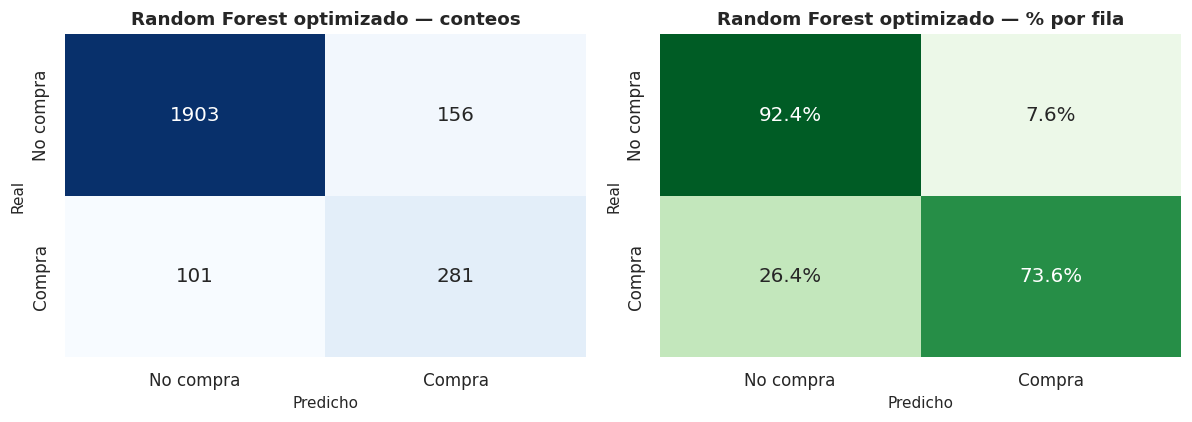

,Antes (inicial),Después (optimizado),Cambio
Accuracy,0.9000,0.8947,-0.0053
F1 macro,0.8115,0.8115,-0.0000
AUC,0.9290,0.9300,+0.0010
Recall (compra),0.6859,0.7356,+0.0497
Precision (compra),0.6788,0.6430,-0.0357


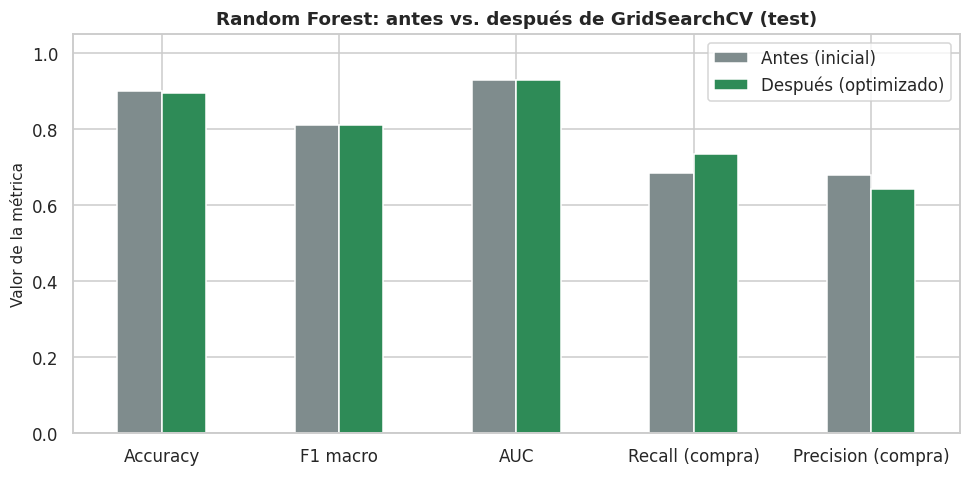

In [ ]:
# ------------------------------------------------------------
# F.2: evaluación del modelo optimizado en test
# ------------------------------------------------------------
modelo_final = gs.best_estimator_            # Pipeline completo ya ajustado con train
y_pred_f = modelo_final.predict(X_test)

def puntuar_pipeline(p, X_):
    if hasattr(p, "predict_proba"):
        return p.predict_proba(X_)[:, 1]
    return p.decision_function(X_)

s_f = puntuar_pipeline(modelo_final, X_test)

print(f"===== {mejor_nombre} OPTIMIZADO — evaluación en test =====\n")
print(classification_report(y_test, y_pred_f, target_names=["No compra", "Compra"], digits=4))
plot_cm(y_test, y_pred_f, f"{mejor_nombre} optimizado")

antes = resultados[mejor_nombre]
despues = {"Accuracy": accuracy_score(y_test, y_pred_f), "F1 macro": f1_score(y_test, y_pred_f, average="macro"),
           "AUC": roc_auc_score(y_test, s_f), "Recall (compra)": recall_score(y_test, y_pred_f),
           "Precision (compra)": precision_score(y_test, y_pred_f)}
comp = pd.DataFrame({"Antes (inicial)": {k: antes[k] for k in despues}, "Después (optimizado)": despues})
comp["Cambio"] = comp["Después (optimizado)"] - comp["Antes (inicial)"]
display(comp.style.format("{:+.4f}", subset=["Cambio"]).format("{:.4f}", subset=["Antes (inicial)", "Después (optimizado)"]))

comp[["Antes (inicial)", "Después (optimizado)"]].plot(kind="bar", figsize=(9, 4.5), rot=0, color=["#7f8c8d", "#2e8b57"])
plt.title(f"{mejor_nombre}: antes vs. después de GridSearchCV (test)")
plt.ylabel("Valor de la métrica"); plt.ylim(0, 1.05); plt.tight_layout(); plt.show()

## 3. Serialización del modelo final con `joblib.dump()`
Serializamos el **Pipeline completo** (preprocesamiento + modelo optimizado). Así, el archivo guardado puede recibir directamente sesiones "crudas", tal como llegarían desde la tienda en línea, sin repetir manualmente el escalado ni la codificación.

In [ ]:
# ------------------------------------------------------------
# F.3: serialización con joblib.dump()
# ------------------------------------------------------------
RUTA_MODELO = "modelo_final_online_shoppers.joblib"
joblib.dump(modelo_final, RUTA_MODELO)

import os
print(f"Modelo guardado en: {RUTA_MODELO} ({os.path.getsize(RUTA_MODELO) / 1024:.0f} KB)")

Modelo guardado en: modelo_final_online_shoppers.joblib (34828 KB)


## 4. Carga con `joblib.load()` y predicción sobre datos nuevos
Simulamos un entorno de producción: cargamos el archivo, comprobamos que reproduce exactamente las predicciones del modelo en memoria y luego predecimos sobre sesiones nuevas.

In [ ]:
# ------------------------------------------------------------
# F.4 (a): carga del modelo y verificación de consistencia
# ------------------------------------------------------------
modelo_cargado = joblib.load(RUTA_MODELO)
pred_cargado = modelo_cargado.predict(X_test)
print("¿El modelo cargado da las mismas predicciones que el original?",
      bool(np.array_equal(pred_cargado, y_pred_f)))
print(f"Accuracy en test del modelo cargado: {accuracy_score(y_test, pred_cargado):.4f}")

¿El modelo cargado da las mismas predicciones que el original? True
Accuracy en test del modelo cargado: 0.8947


In [ ]:
# ------------------------------------------------------------
# F.4 (b): predicción sobre sesiones nuevas (simuladas, con las columnas originales)
# ------------------------------------------------------------
nuevas = pd.DataFrame([
    # Sesión muy comprometida: muchas páginas de producto, PageValues alto, visitante recurrente en noviembre
    dict(Administrative=3, Administrative_Duration=80, Informational=1, Informational_Duration=30,
         ProductRelated=45, ProductRelated_Duration=1800, BounceRates=0.0, ExitRates=0.01, PageValues=48.0,
         SpecialDay=0.0, Month="Nov", OperatingSystems=2, Browser=2, Region=1, TrafficType=2,
         VisitorType="Returning_Visitor", Weekend=0),
    # Visita muy corta, rebote alto, sin valor de página
    dict(Administrative=0, Administrative_Duration=0, Informational=0, Informational_Duration=0,
         ProductRelated=1, ProductRelated_Duration=12, BounceRates=0.2, ExitRates=0.2, PageValues=0.0,
         SpecialDay=0.0, Month="May", OperatingSystems=1, Browser=1, Region=3, TrafficType=1,
         VisitorType="New_Visitor", Weekend=1),
    # Navegación media con algo de valor de página
    dict(Administrative=2, Administrative_Duration=45, Informational=0, Informational_Duration=0,
         ProductRelated=20, ProductRelated_Duration=700, BounceRates=0.01, ExitRates=0.03, PageValues=12.0,
         SpecialDay=0.0, Month="Dec", OperatingSystems=3, Browser=2, Region=2, TrafficType=3,
         VisitorType="Returning_Visitor", Weekend=0),
    # Mucha navegación pero sin valor de página (explora sin llegar a comprar)
    dict(Administrative=5, Administrative_Duration=150, Informational=2, Informational_Duration=60,
         ProductRelated=60, ProductRelated_Duration=2500, BounceRates=0.02, ExitRates=0.05, PageValues=0.0,
         SpecialDay=0.0, Month="Mar", OperatingSystems=2, Browser=2, Region=1, TrafficType=2,
         VisitorType="Returning_Visitor", Weekend=1),
    # Visitante nuevo con valor de página alto
    dict(Administrative=1, Administrative_Duration=20, Informational=0, Informational_Duration=0,
         ProductRelated=15, ProductRelated_Duration=500, BounceRates=0.0, ExitRates=0.02, PageValues=30.0,
         SpecialDay=0.0, Month="Nov", OperatingSystems=2, Browser=2, Region=1, TrafficType=2,
         VisitorType="New_Visitor", Weekend=0),
])

pred_nuevas = modelo_cargado.predict(nuevas)
punt_nuevas = puntuar_pipeline(modelo_cargado, nuevas)
etiqueta_punt = "Probabilidad de compra" if hasattr(modelo_cargado, "predict_proba") else "Puntuación (decision_function)"

salida = nuevas[["Month", "VisitorType", "ProductRelated", "PageValues", "ExitRates"]].copy()
salida[etiqueta_punt] = np.round(punt_nuevas, 3)
salida["Predicción"] = np.where(pred_nuevas == 1, "COMPRA", "No compra")
print("Predicciones del modelo cargado sobre 5 sesiones nuevas (simuladas):")
display(salida)

# Verificación adicional con 5 sesiones reales del test, comparando con la etiqueta real
muestra_t = X_test.sample(5, random_state=SEED)
comparacion = muestra_t[["Month", "VisitorType", "PageValues"]].copy()
comparacion["Real"] = y_test.loc[muestra_t.index].map({0: "No compra", 1: "COMPRA"})
comparacion["Predicción"] = np.where(modelo_cargado.predict(muestra_t) == 1, "COMPRA", "No compra")
print("\nComparación con sesiones reales del test:")
display(comparacion)

Predicciones del modelo cargado sobre 5 sesiones nuevas (simuladas):


,Month,VisitorType,ProductRelated,PageValues,ExitRates,Probabilidad de compra,Predicción
0,Nov,Returning_Visitor,45,48.0,0.01,0.870,COMPRA
1,May,New_Visitor,1,0.0,0.20,0.033,No compra
2,Dec,Returning_Visitor,20,12.0,0.03,0.578,COMPRA
3,Mar,Returning_Visitor,60,0.0,0.05,0.099,No compra
4,Nov,New_Visitor,15,30.0,0.02,0.871,COMPRA



Comparación con sesiones reales del test:


,Month,VisitorType,PageValues,Real,Predicción
9320,Dec,Returning_Visitor,0.00000,No compra,No compra
373,Mar,Returning_Visitor,0.00000,No compra,No compra
6020,Nov,Returning_Visitor,19.23269,No compra,COMPRA
9336,Nov,Returning_Visitor,0.00000,No compra,No compra
2439,May,Returning_Visitor,0.00000,No compra,No compra


> 💡 **Escenario real de uso:** el archivo `.joblib` se puede cargar en una API (por ejemplo con Flask o FastAPI) o en un proceso por lotes de la tienda, para puntuar sesiones en tiempo real y, por ejemplo, mostrar un cupón de descuento a visitantes con alta intención de compra que están por abandonar el sitio, sin reentrenar el modelo cada vez.

In [ ]:
# (Opcional) Descargar el modelo a tu computadora desde Colab
try:
    from google.colab import files
    files.download(RUTA_MODELO)
except Exception:
    print("Descarga automática no disponible fuera de Colab; el archivo quedó en el directorio actual.")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

---
# SECCIÓN G — Conclusiones


## 1. Resumen de resultados

Trabajamos con [N] sesiones únicas (tras eliminar [N_duplicados] duplicados) y solo [X]% de compras. Comparamos Random Forest, XGBoost, Regresión Logística y SVM: el mejor en test por F1 macro fue **[mejor_f1]** ([valor]) y por AUC **[mejor_auc]** ([valor]). Seleccionamos **[mejor_nombre]** por su F1 macro en validación cruzada y lo optimizamos con GridSearchCV ([mejores_hiperparámetros]).

**Efecto de la optimización** (se elige una de las tres frases según el resultado):

- Si el cambio en F1 macro es mayor a +0.003: la optimización mejoró el F1 macro de [F1_ini] a [F1_opt] (+[cambio]).
- Si el cambio es menor a -0.003: la optimización mejoró el F1 macro en validación cruzada, pero en test pasó de [F1_ini] a [F1_opt] ([cambio]); con ~[n_test] sesiones de test y una clase minoritaria pequeña, esa variación entra dentro del ruido esperable.
- En otro caso: la optimización dejó el F1 macro prácticamente igual ([F1_ini] → [F1_opt]), lo que indica que la configuración inicial ya era buena.
El modelo final obtuvo en test accuracy = [valor], AUC = [valor], recall de compra = [valor] y precision de compra = [valor]. El pipeline completo quedó serializado en `[RUTA_MODELO]` y verificamos que, al cargarlo, reproduce las mismas predicciones.

## 2. Lecciones aprendidas

- Con una clase minoritaria (~[X]%), el accuracy engaña: hay que mirar F1 macro, AUC, recall y precision de la clase "compra".
- Eliminar duplicados antes del split y ajustar el escalador solo con train evita que las métricas salgan infladas por fuga de datos.
- Tratar los códigos (`Browser`, `Region`, etc.) como categóricas y no como números evita que los modelos lineales interpreten un orden inexistente.
- Los modelos de ensamble y la regresión logística compiten de cerca: la elección depende también del tiempo de entrenamiento y de qué tan interpretable se necesite el modelo.
- Usar un `Pipeline` hace el flujo reproducible y permite serializar todo junto.
## 3. Limitaciones

- **Desbalance:** pocas sesiones de compra ([n] en test), por lo que métricas como el recall tienen bastante incertidumbre.
- **Cobertura temporal:** los datos solo cubren algunos meses del año y un único sitio web, así que el modelo podría no generalizar a otras temporadas o tiendas.
- **Variables ya agregadas:** `BounceRates`, `ExitRates` y `PageValues` provienen de Google Analytics y están correlacionadas entre sí; además `PageValues` incorpora información muy cercana al resultado.
- Usamos un único split de test; los resultados pueden variar ligeramente con otra semilla.
## 4. Posibles mejoras futuras

- Ajustar el **umbral de decisión** (en lugar de 0.5) según el costo de perder una venta frente al de dar un incentivo innecesario.
- Probar técnicas de remuestreo (SMOTE, undersampling) y comparar contra los pesos de clase.
- Búsqueda de hiperparámetros más amplia (RandomizedSearchCV u Optuna) y calibración de probabilidades.
- Ingeniería de variables (por ejemplo, tiempo promedio por página o ratios de páginas por tipo) y selección de variables.
- Validación con datos de otros periodos y explicabilidad con SHAP.


---
<div align="center">

*Ingeniería del Conocimiento (ISO56B) — UNCP — Facultad de Ingeniería de Sistemas — Semestre V*

**Fin del notebook** ✅

</div>